## DeepISA tutorial

DeepISA is an end-to-end Python package for training DNA sequence models and quantifying transcription factor (TF) importance and cooperativity across the genome. It uses a dilated convolutional neural network to predict log-transformed functional assay signals (e.g., CAGE-seq, ATAC-seq, DNase-seq, SuRE-seq, STARR-seq) from the DNA sequences of candidate regulatory elements (CREs). 

The package then performs In Silico Ablation (ISA), which computationally masks specific TF binding motifs and measures how individual or combined motif removal changes predicted regulatory activity. By comparing these effects, DeepISA places TF interactions on a continuum from redundancy to synergy, revealing consistent principles of gene regulation.

TODO:  because deepISA generate large files, it always write minibatches directly to hard disk. You can load back the result and play with it later.

To run the deepISA pipeline, you need to prepare the following files to run the deepISA pipeline:


1. Mandatory Genomic Resources

* Reference Genome (.fa): A FASTA file of the genome (the tutorial uses hg38). This is required to convert genomic locations to actual sequences

* TF Binding Annotations (.bb): Specifically, JASPAR 2026 genome-wide predictions in bigBed format. This allows the tool to know where the transcription factor motifs are located for ablation.


2. Primary Input Data (.bed): regulatory region and signal

You need your candidate regulatory regions and their activity levels. You have two main ways to provide this:

* Option A (Pre-quantified): A CSV or BED file containing genomic coordinates (chrom, start, end) and a column with pre-calculated signal intensities (e.g., TPM or read counts from CAGE-seq). Make sure that the signal intensity is NOT log-transformed.

* Option B (BigWig signal Tracks): A BED file of coordinates plus the corresponding BigWig (.bw) files. The pipeline will then quantify the signals for you.


3. Optional Enrichment Data

* ReMap 2022 (.bed): A curated atlas of ChIP-seq peaks. You use this if you want to filter your results to only include motifs that have ChIP-Seq evidence of binding in a specific cell type.

* Expressed TF List: A list of TFs known to be active in your cell line. This is highly recommended to reduce false positives by ensuring you only analyze TFs that are actually present.

4. Pre-trained Model (Alternative to Training):

* Weights File (.pt): If you don't want to train a new model from scratch, you can provide a pre-trained PyTorch model (like the model_blympho.pt mentioned) to go straight to the In Silico Ablation (ISA) analysis.

## Basic imports and data loading

Prepare the following files for the deepISA pipeline:

* Reference genome: [hg38](https://hgdownload.cse.ucsc.edu/goldenpath/hg38/bigZips/hg38.fa.gz)

* Jaspar: [JASPAR 2026](https://mencius.uio.no/JASPAR/JASPAR_TFBSs/2026/JASPAR2026_hg38.bb) is genome-wide predictions of TF binding sites in bigBed format for hundreds of TFs, based on high-quality TF Position Frequency Matrices. Other versions (JASPAR 2022, 2024) may cause compatibility issues.

* ReMap (optional): [ReMap 2022](https://remap.univ-amu.fr/storage/remap2022/hg38/MACS2/remap2022_nr_macs2_hg38_v1_0.bed.gz) is a curated atlas of 182 million DNA-TF binding peaks, derived from 8103 human ChIP-seq datasets, covering hundreds of TFs across hundreds of cell lines and tissues.

In [1]:
import os
from loguru import logger
import pandas as pd
from deepISA.utils import get_data_resource
from deepISA.utils import find_available_gpu


FASTA_PATH = "/maps/projects/ralab/people/pcr980/Resource/Hg38/hg38.fa"
JASPAR_BB = "/maps/projects/ralab/people/pcr980/Resource/JASPAR/JASPAR2026_hg38.bb"
CELL_FACET = "B_lymphoblastoid"
SEQ_LEN = 600
DEVICE=find_available_gpu()
MODE="dual"


2026-09-15 12:00:54.999 | WARNING  | deepISA.utils:find_available_gpu:76 - No CUDA GPUs detected. Falling back to CPU.


## QuickStart, the fast track

regions_pos.bed comes containing randomly selected 1000 candidate regulatory regions with CAGE signal, for B_lymphoblastoid cell line. 

Subsetting regulatory regions aims to accelerate training for tutorial. The model performance is supposed to improve with full set of regulatory regions.

On output file names:
* "motif_": information about individual TF binding sites
* "tf_": TF features aggregated from all binding sites
* "_t0": track_idx. 

In [2]:
# Step 1: load data, train a regression model with classification regularization
bed_path = get_data_resource("regions_pos_with_count.csv")
df_regions = pd.read_csv(bed_path)
df_regions.head()


,chrom,start,end,target_reg
0,chr12,55725882,55726482,13.0
1,chr19,36028217,36028817,13.0
2,chr1,7403363,7403963,13.0
3,chr2,68062734,68063334,337.0
4,chr7,151632560,151633160,54.0


In [3]:
from deepISA.quickstart import QuickStart

pipe = QuickStart(
    results_dir="./QuickStart",
    fasta_path=FASTA_PATH,
    df_input=df_regions, # regions to analyze, negative region is optional
    device=DEVICE,
)

2026-09-15 12:00:55 | INFO    | setup_logger:146 - Logger initialized. Logs redirected to: ./QuickStart/workflow.log


/maps/projects/ralab/people/pcr980/miniforge3/envs/deepISA-v2/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [4]:
# This is default parameters for model configuration
model_config = {
    "seq_len": SEQ_LEN,
    "ks": [15,9,9,9,9], # kernel size
    "cs": [64,64,64,64,64], # channel size
    "ds": [1,2,4,8,16],
    "dropout": 0.1
}

pipe.define_model(model_config, mode=MODE)



2026-09-15 12:00:55 | INFO    | define_model:155 - Internal Conv model initialized. Receptive field: 255


2026-09-15 12:00:55 | INFO    | train:188 - Compiling training data...
2026-09-15 12:00:55 | INFO    | compile_training_data:131 - Scenario 1: Using provided signal column 'target_reg'
2026-09-15 12:00:55 | INFO    | compile_training_data:138 - No class column provided. Inferring target_class (signal > 0).
2026-09-15 12:00:55 | INFO    | _balance_and_label:31 - Initial counts: 1000 positives, 0 negatives.
2026-09-15 12:00:55 | INFO    | _balance_and_label:34 - Sampling 1000 extra negatives from background pool.
2026-09-15 12:00:56 | INFO    | compile_training_data:152 - Applying log1p transformation to target_reg.
2026-09-15 12:01:08 | INFO    | _report_metrics:134 - [val]  epoch=0  loss=7.9808  pearson=-0.2875  accuracy=0.5288
2026-09-15 12:01:08 | INFO    | _report_metrics:134 - [train]  epoch=0  loss=10.6955
2026-09-15 12:01:08 | INFO    | _test:168 - Running final evaluation...
2026-09-15 12:01:08 | INFO    | _report_metrics:134 - [test]  loss=7.4042  pearson=-0.2450  accuracy=0.40

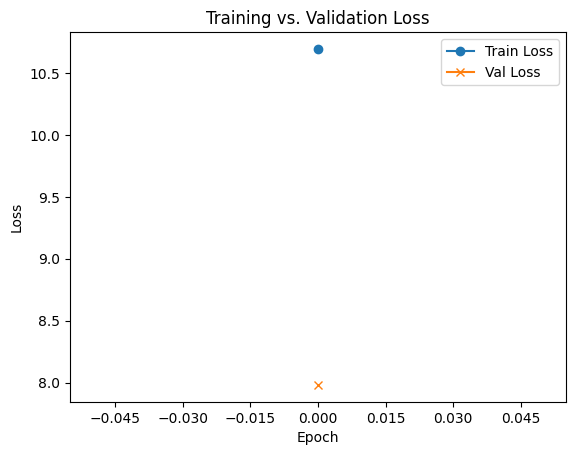

2026-09-15 12:01:09 | INFO    | train:209 - Training complete. Check ./QuickStart/Models for model_best.pt
2026-09-15 12:01:09 | INFO    | load_checkpoint:221 - Successfully loaded checkpoint: model_best.pt


Conv(
  (convs): ModuleList(
    (0): Conv1d(4, 64, kernel_size=(15,), stride=(1,))
    (1): Conv1d(64, 64, kernel_size=(9,), stride=(1,), dilation=(2,))
    (2): Conv1d(64, 64, kernel_size=(9,), stride=(1,), dilation=(4,))
    (3): Conv1d(64, 64, kernel_size=(9,), stride=(1,), dilation=(8,))
    (4): Conv1d(64, 64, kernel_size=(9,), stride=(1,), dilation=(16,))
  )
  (dropout): Dropout(p=0.1, inplace=False)
  (regression_head): Linear(in_features=22144, out_features=1, bias=True)
  (classification_head): Linear(in_features=22144, out_features=1, bias=True)
)

In [5]:

# This is default parameters for trainer configuration
trainer_config={
    "epochs": 1,
    "batch_size": 2048,
    "patience": 5,
    "min_delta": 0.001, # minimum change in the monitored metric to qualify as an improvement
    "learning_rate": 1e-3,
    "save_one_fourth": False,
    "save_one": False
}


# specify the column in df_regions that contains the signal, the regression prediction target
# make sure this column is not log-transformed, as deepISA will apply log transformation internally
pipe.train(trainer_config, 
           target_reg_col="target_reg")

pipe.load_checkpoint("_best")

In [6]:
# This is default parameters for isa_config
isa_config = {
    "motif_score_threshold": 600,
    "remap_path": None,
    "min_count":10,
    "n_null_samples": 2000,
    "num_regions_per_batch": 400,
    "pred_batch_size": 8192,
    "null_percentile": 80,
    "q_val_thresh":0.1,
    "receptive_field":255
}

pipe.run_isa(
    jaspar_path=JASPAR_BB,
    isa_config=isa_config,
    start_from="map_motifs"
)

2026-09-15 12:01:09 | INFO    | run_isa:268 - 1000 positive regions identified from input data. Use as input for ISA.
2026-09-15 12:01:09 | INFO    | run_isa:280 - Running stage: map_motifs
2026-09-15 12:01:09 | INFO    | map_motifs:153 - Starting JASPAR motif mapping.
2026-09-15 12:01:09 | INFO    | annotate:102 - Processing region 0-1000 / 1000
2026-09-15 12:01:26 | INFO    | map_motifs:163 - Mapped motifs saved to ./QuickStart/Data/motif_locs.csv.
2026-09-15 12:01:26 | INFO    | map_motifs:167 - Non-motif regions saved to ./QuickStart/Data/non_motif_locs.csv.
2026-09-15 12:01:26 | INFO    | run_isa:302 - Running stage: calc_orig
2026-09-15 12:01:27 | INFO    | calc_pred_orig:53 - Saved region original predictions: ./QuickStart/Data/pred_orig.csv (1000 regions)
2026-09-15 12:01:27 | INFO    | run_isa:319 - Running stage: single_isa
2026-09-15 12:01:27 | INFO    | run_single_isa:79 - Single ISA started. Total rows to process: 3707
2026-09-15 12:01:29 | INFO    | run_single_isa:107 - S

/maps/projects/ralab/people/pcr980/deepISAv2/src/deepISA/score/aggregate_isa.py:253: RuntimeWarning: invalid value encountered in scalar divide
  coop_score = interactions.sum() / np.abs(interactions).sum()


2026-09-15 12:01:47 | INFO    | calc_coop_score:273 - Coop score (tf_pair) saved to ./QuickStart/Data/coop_tf_pair_t0.csv


/maps/projects/ralab/people/pcr980/deepISAv2/src/deepISA/score/aggregate_isa.py:253: RuntimeWarning: invalid value encountered in scalar divide
  coop_score = interactions.sum() / np.abs(interactions).sum()
/maps/projects/ralab/people/pcr980/deepISAv2/src/deepISA/score/aggregate_isa.py:253: RuntimeWarning: invalid value encountered in scalar divide
  coop_score = interactions.sum() / np.abs(interactions).sum()


2026-09-15 12:01:48 | INFO    | calc_coop_score:273 - Coop score (tf) saved to ./QuickStart/Data/coop_tf_t0.csv
2026-09-15 12:01:48 | INFO    | run_isa:422 - ISA execution and aggregation complete.


In [7]:
pipe.report() 

2026-09-15 12:01:48 | INFO    | report:436 - Generating comprehensive reports and plots...
2026-09-15 12:01:55 | WARNING | plot_dna_mediated_ppi:249 - No overlapping pairs found between results and binding matrix.
2026-09-15 12:01:55 | WARNING | plot_dna_mediated_ppi:249 - No overlapping pairs found between results and binding matrix.
2026-09-15 12:01:55 | INFO    | report:505 - Report complete. All plots saved to ./QuickStart/Plots


While `jaspar_path` is the only required argument for `.run_isa()`, providing a list of `expressed_tfs` is highly recommended for biological relevance. By passing a list of TFs known to be expressed in your specific cell line, the model filters out motifs of TFs that aren't present and therefore cannot be functional. We also provide function `get_expressed_tfs()` to estimate expressed TF list from the candidate regions and genome-wide bigwig signals. See section _____ for more information.

Variations of QuickStart usage:
* If you only have the regions and a bigwig file, but you haven't quantified it yourself, we can quantify it for you (also see section _____), just privide the bw_path in `.train()`.

* If you have a pretrained model already, just provide the model path, and we start from `.run_isa()`.

In [8]:
# If you have a pretrained model:
import torch
from deepISA.quickstart import QuickStart

pipe = QuickStart(
    results_dir="./QuickStart_pretrained",
    fasta_path=FASTA_PATH,
    df_input=df_regions,
    device=DEVICE,
)


2026-09-15 12:01:55 | INFO    | setup_logger:146 - Logger initialized. Logs redirected to: ./QuickStart_pretrained/workflow.log


In [9]:
from deepISA.model.cnn import Conv
# load pretrained model
pretrained_model_path = get_data_resource("model_blympho.pt") 
pretrained_model=Conv(mode=MODE, model_config=model_config)
pretrained_model.load_state_dict(torch.load(pretrained_model_path, weights_only=False))

pipe.define_model(model_obj=pretrained_model, mode=MODE)
# Skip .train()
pipe.run_isa(jaspar_path=JASPAR_BB, isa_config=isa_config)

pipe.report()

RuntimeError: Attempting to deserialize object on a CUDA device but torch.cuda.is_available() is False. If you are running on a CPU-only machine, please use torch.load with map_location=torch.device('cpu') to map your storages to the CPU.

## Details of workflow: step by step

Let's unfold the workflow that QuickStart wraps up.

In [ ]:
# set up logger to save logs in the results directory
from deepISA.utils import setup_logger
from deepISA.model.preprocess import compile_training_data
from deepISA.utils import get_data_resource
import os
RESULTS_DIR = "Step_by_step_res"
os.makedirs(RESULTS_DIR, exist_ok=True)

setup_logger(RESULTS_DIR)
logger.info("Starting deepISA tutorial")


### 1. Prepare data for deep learning

This step uses function `compile_training_data()`. It takes in your BED file as a `pandas.DataFrame` and returns labeled data for downstream deep learning.

The input DataFrame must include the following column names:

* "chrom": chromosome name
* "start": start coordinate
* "end": end coordinate

Ensure that all intervals satisfy: end - start == target_input_length

Multiple preprocessing workflows are supported. You may either provide pre-quantified data (option 1), or use the built-in labeling function, simply by passing additional arguments to `compile_training_data()` (option 2).

#### Option 1: BED file with pre-quantified signals

Use this mode if your have already quantified the signals (e.g., TPM or read counts) for the candidate regions. The pipeline will automatically sample non-functional background regions to balance the dataset, so that number of positive and negative regions equalize.

These background regions are sampled genome-wide, excluding candidate Cis-Regulatory Elements ([cCREs](https://www.nature.com/articles/s41586-025-09909-9)), exons and the ENCODE blacklist.

Make sure that your quantified signals are not log-transformed, since compile_training_data() will automatically perform log transformation. Hence, the model will always output log-transformed signal predictions.

By default, `rc_aug==True`, to apply reverse complement data augmentation. This is highly recommended for stable training, unless you are training on strand-aware data like single-stranded CAGE-Seq signals.

In [ ]:
# read an internal example file
df_pos = pd.read_csv(get_data_resource("regions_pos_with_count.csv"))
df_pos.head()

In [ ]:
df_data = compile_training_data(
    df=df_pos, 
    fasta_path=FASTA_PATH,
    out_dir =os.path.join(RESULTS_DIR, "Data"),
    seq_len=SEQ_LEN,
    # your column name for TPM/count/signal, make sure it is not log transformed.
    target_reg_col="target_reg",
    rc_aug=True # Highly recommended, unless you are training on single strand CAGE data.
)
df_data.head() 

One columns are is added by function `compile_training_data()`: 
* "target_class": classification target, 1 for positive regions (regulatory elements), 0 for negative regions.

In [ ]:
# define model:
from deepISA.model.cnn import Conv

model_cfg = {
    'seq_len': SEQ_LEN, # make sure this is the same as in compile_training_data
    'ks': [15,9,9,9,9],
    'cs': [64,64,64,64,64],
    'ds': [1, 2, 4, 8, 16]
}

model = Conv(
    mode=MODE, # Can be 'regression', or 'dual'
    model_config=model_cfg
)

print(model)

#### Option 2: BED file + BigWig signal tracks

If you have genomic coordinates of regulatory elements, and want to quantify signals directly from BigWig files. The pipeline estimates a noise threshold from background regions to define the classification target.

Just pass a list of bigwig file paths to the optional parameter `bw_paths`.
  

### 2 Train convolutional neural network

This step uses function `train_model()`. It takes in the labeled data frame, performs train-val-test split, then train a exponentially dilated convolutional neural network. The main architecture highly resembles BPNet, but doesn't contain the per-base profile prediction for faster training.

Early stopping is enabled by default, so it is design to "overfit" the validation set. Use `evaluate_model()` to get the unbiased performance estimate.

For hyperparameter tuning, `train_model()` will automatically save a "training_log.csv" to record the learning curve.


In [ ]:
from deepISA.model.train import train_model

trainer_config={
    "epochs": 10,
    "batch_size": 128,
    "patience": 5,
    "min_delta": 0.001, # minimum change in the monitored metric to qualify as an improvement
    "learning_rate": 1e-3,
    "save_one_fourth": False,
    "save_one": False
}

train_model(
    model=model,
    device=DEVICE,
    train_dat_dir=os.path.join(RESULTS_DIR, "Data"), # the directory compile_training_data outputs to
    mode=MODE,
    model_dir=os.path.join(RESULTS_DIR, "Model"),
    trainer_config=trainer_config
)

In [ ]:
# load the best model for future analysis
import torch
model_path = os.path.join(RESULTS_DIR, "Model", "model_best.pt")
model.load_state_dict(torch.load(model_path, weights_only=True))

### 3. Map motifs for all candidate regulatory regions with positive signal

This step uses function `map_motif()`. It takes in the candidate regulatory regions with positive signal, and returns all the motif locations according to [JASPAR 2026](https://mencius.uio.no/JASPAR/JASPAR_TFBSs/2026/JASPAR2026_hg38.bb) database, thresholded by motif matching score, for each regulatory region. 

The JASPAR matching score (range: 100-1000) quantifies how well a short DNA sequence aligns with a transcription factor motif from the JASPAR database, using a position weight matrix to compute a similarity score at each position. The default Jaspar score is 500, meaning the p-value of motif matching is 1e-5.

In [ ]:
from deepISA.score.mapper import map_motifs
#TODO: write preprocess_remap(cell_type). 


map_motifs(
    regions_df=df_pos, 
    jaspar_path=JASPAR_BB,
    motif_outpath=os.path.join(RESULTS_DIR,"motif_locs.csv"),
    non_motif_outpath=os.path.join(RESULTS_DIR,"non_motif_locs.csv"),
    expressed_tfs=None, # set to None for tutorial, but providing expressed_tf_list is highly recommended for real analysis to reduce false positives.
    motif_score_thresh=500,
    remap_path=None,
)

# read the mapped motif locations
df_motif_locs = pd.read_csv(os.path.join(RESULTS_DIR,"motif_locs.csv"))
df_motif_locs.head()

In [ ]:
df_non_motif_locs = pd.read_csv(os.path.join(RESULTS_DIR,"non_motif_locs.csv"))
df_non_motif_locs.head()

One way to reduce false positive of TF binding site is to retain only those with overlapping ChIP-Seq peak recorded in [ReMap 2022](https://remap2022.univ-amu.fr/) database. It is essentially a giant bed file containing genomic locations of ChIP-Seq peak for thousands of TFs in hundreds of cell lines. By setting `remap_path=YOUR_REMAP_PATH`, function `map_motif()` will return an additional column "remap_evidence" of boolean values, indicating whether each motif is supported by the ChIP-Seq peak of the same TF according to ReMap. Then you can subset manually to contain only the motifs supported by ChIP-Seq.

However, not all TFs expressed in each cell line have a corresponding ChIP-Seq experiment, thus subsetting by ReMap evidence risks losing valid TF binding sites simply due to lack of ChIP-Seq experiment recorded in ReMap.

A more lenient motif filtering strategy: filtering by TF gene expression level since only expressed TFs can exert influence. By passing `expressed_tfs=YOUR_EXPRESSED_TF_LIST`, function `map_motif()` will only return the motifs of TFs in the `expressed_tfs`.

In [ ]:
# from deepISA.score.infer_tf_expr import get_expressed_tfs

# # Define the same BigWig tracks used for training
# bw_paths = [
#     f"{BW_DIR}/{CELL_FACET}.minus.bw", 
#     f"{BW_DIR}/{CELL_FACET}.plus.bw"
# ]

# # Infer the list of expressed TFs based on a noise threshold
# expressed_tf_list = get_expressed_tfs(
#     bw_paths=bw_paths, 
#     percentile=99
# )

# len(expressed_tf_list)

### 4. Run single ISA to quantify TF importance

This step first uses function `run_single_isa()`. It takes in a well-trained model and the filtered motif locations, and output the in silico ablation scores of all motifs directly to hard disk. This step is computation heavy, thus GPU is necessary here. 

Then we use function `calc_tf_importance()` to aggregate all the motif ISA scores for each TF. Aggregation methods include mean, median and signed Kolmogorov-Smirnov (KS) statistics. KS requires sufficient instances for accurate calculation, thus it produces a warning if fewer than 5 instances exist for a TF.

In [ ]:
from deepISA.score.single_isa import run_single_isa, calc_tf_importance

# 3. Compute Single-Motif ISA
run_single_isa(
    model=model, 
    fasta=FASTA_PATH,
    motif_locs_path=os.path.join(RESULTS_DIR, "motif_locs.csv"),
    non_motif_locs_path=os.path.join(RESULTS_DIR, "non_motif_locs.csv"),
    single_isa_outpath=os.path.join(RESULTS_DIR, "motif_single_isa.csv"),
    null_isa_outpath=os.path.join(RESULTS_DIR, "null_isa.csv"),
    pred_orig_outpath=os.path.join(RESULTS_DIR, "pred_orig.csv"),
    device=DEVICE,
    null_percentile=80,
    num_regions_per_batch=200, # Adjust based on your GPU memory, larger batch size will speed up the process but use more memory
    pred_batch_size=1024,
)

df_single_isa = pd.read_csv(os.path.join(RESULTS_DIR, "motif_single_isa.csv"))
df_single_isa.head()

In [ ]:
df_null_isa = pd.read_csv(os.path.join(RESULTS_DIR, "null_isa.csv"))
df_null_isa.head()

In [ ]:
# 4: aggregate single ISA to yield tf importance

single_isa_path = os.path.join(RESULTS_DIR, "motif_single_isa.csv")
null_isa_path=os.path.join(RESULTS_DIR, "null_isa.csv")
output_path=os.path.join(RESULTS_DIR, "tf_importance.csv")

calc_tf_importance(single_isa_path,
                   null_isa_path,
                   output_path,
                   min_count=10,
                   null_percentile=95)

df_importance = pd.read_csv(os.path.join(RESULTS_DIR, "tf_importance.csv"))
df_importance.head()


### 5. Run combinatorial ISA for TF pair cooperativity

This step first uses function `run_combi_isa()`. It takes in a well-trained model, the filtered motif locations, and model receptive field. Then it performs combinatorial ISA for all motifs on same regulatory region within distance of the model receptive field. Models trained by deepISA package have attribute `.rf` for receptive field.

Then we use function `calc_coop_score()` to aggregate the raw combinatorial ISA results and obtain cooperativity score. Note, this aggregation can be performed on both TF-pair and TF level, by specifying `level='tf_pair'`, or `level='tf_pair'`. 

In the cooperativity score report, TF pairs are always alphabetically sorted and concatenated by "|".

In [ ]:
from deepISA.score.combi_isa import run_combi_isa


run_combi_isa(
    model=model,
    fasta=FASTA_PATH,
    single_isa_path=os.path.join(RESULTS_DIR, "motif_single_isa.csv"),
    outpath=os.path.join(RESULTS_DIR, "motif_combi_isa.csv"),
    device=DEVICE,
    receptive_field=255, # make sure this matches the receptive field of your model
    pred_orig_path=os.path.join(RESULTS_DIR, "pred_orig.csv"),
    num_regions_per_batch=200,
    pred_batch_size=1024
)


In [ ]:
from deepISA.score.combi_isa import run_null_interaction

run_null_interaction(
    model=model,
    fasta=FASTA_PATH,
    non_motif_locs_path=os.path.join(RESULTS_DIR, "non_motif_locs.csv"),
    combi_isa_path=os.path.join(RESULTS_DIR, "motif_combi_isa.csv"),
    pred_orig_path=os.path.join(RESULTS_DIR, "pred_orig.csv"),
    outpath=os.path.join(RESULTS_DIR, "null_interaction.csv"),
    device=DEVICE
)


In [ ]:
from deepISA.score.combi_isa import add_interaction

add_interaction(
    combi_isa_path=os.path.join(RESULTS_DIR, "motif_combi_isa.csv"),
    null_interaction_path=os.path.join(RESULTS_DIR, "null_interaction.csv"),
    null_isa_path=os.path.join(RESULTS_DIR, "null_isa.csv"),
    null_percentile=80)

In [ ]:

from deepISA.score.combi_isa import  calc_coop_score

combi_isa_path = os.path.join(RESULTS_DIR, "motif_combi_isa.csv")
null_isa_path = os.path.join(RESULTS_DIR, "null_isa.csv")
null_interaction_path = os.path.join(RESULTS_DIR, "null_interaction.csv")
calc_coop_score(combi_isa_path,
                null_interaction_path,
                outpath=os.path.join(RESULTS_DIR, "coop_tf_pair.csv"),
                level="tf_pair",
                null_percentile=80,
                min_count=10,
                q_val_thresh=0.1)

calc_coop_score(combi_isa_path,
                null_interaction_path,
                outpath=os.path.join(RESULTS_DIR, "coop_tf.csv"),
                level="tf",
                null_percentile=80,
                min_count=10,
                q_val_thresh=0.1)


### 6. Plot results

deepISA package provide deepCompARE style analysis and plots, for reproducibility and sanity check.

In [ ]:
# load result data
import os
import pandas as pd
RESULTS_DIR = "Step_by_step_res"
df_raw_combi = pd.read_csv(os.path.join(RESULTS_DIR, "motif_combi_isa.csv"))
df_coop_pair = pd.read_csv(os.path.join(RESULTS_DIR, "coop_tf_pair.csv"))
df_coop_tf = pd.read_csv(os.path.join(RESULTS_DIR, "coop_tf.csv"))

#### Observation 1: interaction decays along distance

In [ ]:
from deepISA.plot.interaction import (
    plot_interaction_decay, 
)

from deepISA.plot.null import (
    plot_null_isa,
    plot_null_interaction,
)

plot_interaction_decay(df_raw_combi, figsize=(4, 3))

In [ ]:
plot_null_interaction(os.path.join(RESULTS_DIR, "null_interaction.csv"))


In [ ]:

# write plot null_isa and plot_null_interaction
plot_null_isa(os.path.join(RESULTS_DIR, "null_isa.csv"))

#### Observation 2: TF-pair level cooperativity 

In [ ]:
from deepISA.plot.cooperativity import (
    hist_coop_score,
    heatmap_coop_score,
    plot_motif_distance_by_category
)

hist_coop_score(df_coop_pair, figsize=(4, 3))

In [ ]:
# Height for labels can be set based on max frequency
heatmap_coop_score(df_coop_pair, figsize=(8, 8))

In [ ]:
plot_motif_distance_by_category(df_coop_pair, figsize=(4, 3))

#### Observation 3: TF level cooperativity

In [ ]:
from deepISA.plot.tf import (
    plot_motif_gc_by_coop,
    plot_coop_vs_importance,
    plot_partner_specificity
)

df_coop_tf = pd.read_csv(os.path.join(RESULTS_DIR, "coop_tf.csv"))
plot_motif_gc_by_coop(df_coop_tf)

In [ ]:
# Plot cooperativity score vs importance score 
df_importance = pd.read_csv(os.path.join(RESULTS_DIR, "tf_importance.csv"))
plot_coop_vs_importance(df_coop_tf, df_importance, figsize=(4, 3))

In [ ]:
plot_partner_specificity(df_coop_pair, df_coop_tf,min_partners=1)

### 7. Explore association with external data

Tell user dimers "::" are removed from PPI validation.
Only for human

#### Observation 4: TF family behavior

In [ ]:
from deepISA.explore.tf_family import (
    plot_coop_by_tf_pair_family,
    plot_coop_by_dbd,
    plot_intra_family_coop_score
)

df_res=plot_coop_by_tf_pair_family(df_coop_pair)

In [ ]:
df_res=plot_intra_family_coop_score(df_coop_pair)

In [ ]:
df_res=plot_coop_by_dbd(df_coop_tf)

In [ ]:
from deepISA.explore.tf_pair_ppi import (
    plot_ppi_enrichment,
    plot_cofactor_recruitment,
    plot_dna_mediated_ppi
)


plot_ppi_enrichment(df_coop_pair, rank_by="coop_score")

In [ ]:
plot_ppi_enrichment(df_coop_pair, rank_by="p_val")

In [ ]:
plot_dna_mediated_ppi(df_coop_pair, rank_by="coop_score")

In [ ]:
plot_dna_mediated_ppi(df_coop_pair, rank_by="p_val")

In [ ]:
# Cooperativity between TF pairs of same family
df_res=plot_cofactor_recruitment(df_coop_pair)

Validate with TF functions: gini index and known TF functional categories.

In [ ]:
from deepISA.explore.tf_function import (
    plot_usf_pfs,
    plot_cell_specificity
)

plot_usf_pfs(df_coop_tf)

In [ ]:
plot_cell_specificity(df_coop_tf)

### 8. Discover motifs de novo (step by step)

Everything the QuickStart motif-discovery methods do is also available as plain functions in `deepISA.discover`. Running the steps individually makes errors easy to localize (and each step's output easy to inspect), and shows exactly what to embed if you want motif discovery inside your own workflow. The QuickStart wrappers in the *Motif Discovery* chapter below call precisely these functions.

Attribution, NPZ/H5 preparation and result parsing are pure Python. Only the two heavy steps need external CLIs (install what you need):
```
pip install modisco-lite      # provides the `modisco` CLI
# Fi-NeMo: https://github.com/kundajelab/Fi-NeMo
```

> **Unknown bases (N):** `one_hot_encode` maps `N` to all-zero columns, which the attribution backend rejects (`X must be one-hot encoded ... cannot have unknown characters`). Two layers handle this: `run_modisco` **drops** N-containing regions up front (`drop_N=True`, only while they stay under `max_drop_frac`=20% of the input -- beyond that they are kept), and `compute_attribution` imputes any N that still slips through with random ACGT (seeded, logged) as a fallback.


In [ ]:
from deepISA.utils import load_fasta, get_sequences_from_df, one_hot_encode
from deepISA.discover import compute_attribution, load_motifs
from deepISA.discover import prepare_modisco_input, run_modisco

# Regions of interest -> one-hot (N, 4, L); same encoding QuickStart uses.
# For a classification/dual model you may want to subset positives first,
# e.g. df_pos = df_data[df_data["target_class"] == 1]
fasta = load_fasta(FASTA_PATH)
X = one_hot_encode(get_sequences_from_df(df_pos, fasta))
X.shape


In [ ]:
# Curate the input set (run_modisco does this by default): drop regions
# containing N, then keep the top 10% by activity.
from deepISA.discover import select_top_regions, drop_non_acgt_regions

df_sel, n_dropped = drop_non_acgt_regions(df_pos, FASTA_PATH)   # drop assembly gaps

# activity = model prediction on track 0 (or pass a measured-signal column)
model.eval()   # dropout off -> deterministic ranking
with torch.no_grad():
    xb = torch.tensor(one_hot_encode(get_sequences_from_df(df_sel, fasta))).to(DEVICE)
    activity = model(xb)[:, 0].cpu().numpy()

df_pos_modisco = select_top_regions(df_sel, activity, top_frac=0.1)
print(f"{len(df_pos)} -> {len(df_pos_modisco)} regions (dropped {n_dropped} with N)")

# attribution below uses the curated set (set top_frac=None above, or skip the
# N drop, to attribute everything instead)
df_attr = df_pos_modisco
X = one_hot_encode(get_sequences_from_df(df_attr, fasta))
X.shape

In [ ]:
# Step 1: per-position DeepLIFT-SHAP (tangermeme) -> attribution H5.
# One attribution per output track, stacked as (T, N, 4, L).
ATTR_H5 = os.path.join(RESULTS_DIR, "attr.h5")
compute_attribution(
    model=model,                       # the trained model loaded in section 2
    seqs_ohe=X,
    tracks=[0, 1] if MODE == "dual" else [0],
    n_refs=100,        # dinucleotide-shuffled references per sequence
    batch_size=64,     # sequences per batch (GPU memory trade-off)
    device=DEVICE,
    save_h5_path=ATTR_H5,
    ids=df_attr["region"].astype(str).tolist() if "region" in df_attr.columns else None,
)


In [ ]:
# Step 2: attribution H5 -> the NPZ pair the `modisco` CLI consumes.
# track_index picks ONE output track: regression and classification
# attributions must not be averaged (averaging is biologically meaningless).
ohe_npz, hyp_npz = prepare_modisco_input(
    h5_path=ATTR_H5,
    out_dir=os.path.join(RESULTS_DIR, "modisco_input"),
    track_index=0,
)


In [ ]:
# Step 3: run tf-modisco-lite (external CLI). window=None means the -w
# flag uses the full region length (e.g. 600) -- sequences are NOT trimmed.
MODISCO_H5 = os.path.join(RESULTS_DIR, "modisco_results.h5")
run_modisco(
    ohe_npz=ohe_npz,
    hyp_npz=hyp_npz,
    out_h5=MODISCO_H5,
    n_seqlets=50000,
    window=None,
)


In [ ]:
# Step 4: read the discovered motifs back from the results H5.
motifs = load_motifs(MODISCO_H5, task_name="discovery", target_len=40)
for motif_id, m in motifs.items():
    print(motif_id, "| seqlets:", m["num_seqlets"], "| CWM:", m["cwm"].shape)


**Optional: scan for motif hits with Fi-NeMo.** Finds occurrences of the discovered motifs in the same regions, reusing the attribution from step 1. Requires the `finemo` CLI.

In [ ]:
from deepISA.discover import read_attribution_h5
from deepISA.discover import build_finemo_input, run_finemo_scan, load_hits_with_annotation

# Attribution H5 -> Fi-NeMo input NPZ (same single-track choice as above).
seqs, hyp, _ = read_attribution_h5(ATTR_H5, track_index=0)     # both (N, 4, L)
finemo_npz = build_finemo_input(
    seqs_ohe=seqs,
    hyp_scores=hyp,
    out_dir=os.path.join(RESULTS_DIR, "finemo"),
)
hits_tsv = run_finemo_scan(
    npz_path=finemo_npz,
    out_dir=os.path.join(RESULTS_DIR, "finemo"),
    motif_db_h5=MODISCO_H5,
    lam=0.7,           # importance vs position-precision trade-off
    max_steps=10000,
)
df_hits = load_hits_with_annotation(hits_tsv, MODISCO_H5)
df_hits.head()


**Optional: HTML report + MEME export.** `run_motif_report` builds the standard tf-modisco-lite report (logos, seqlet tables). Pass `meme_db=<path to a MEME database>` (e.g. JASPAR) to also annotate every discovered motif with its best TOMTOM match.

In [ ]:
from deepISA.discover import run_motif_report, cwm_to_meme

report_dir = run_motif_report(
    modisco_h5=MODISCO_H5,
    out_dir=os.path.join(RESULTS_DIR, "motif_report"),
    meme_db=None,      # e.g. "JASPAR2024.meme" for TOMTOM annotation
)
# Discovered motifs as a standalone MEME file (for external TOMTOM runs):
cwm_to_meme(motifs, os.path.join(RESULTS_DIR, "discovered_motifs.meme"))
print(f"Report: {report_dir}/index.html")


## Motif Discovery (tf-modisco-lite + Fi-NeMo)

DeepISA can discover motifs *de novo* from the trained model's attributions with **tf-modisco-lite** and **Fi-NeMo** — and feed them straight into ISA. It is a **`method` option of `run_isa`**: discovered motif hits are converted into the same `motif_locs.csv` format the JASPAR mapper produces, so every downstream stage (single ISA → combinatorial ISA → cooperativity) runs unchanged.

**Attribution backend**: per-position DeepLIFT-SHAP computed with [tangermeme](https://github.com/jmschrei/tangermeme) (PyTorch-native) against per-sequence dinucleotide-shuffled references. N-containing regions are dropped up front (while under 20% of the input); any N that still reaches attribution is imputed with random ACGT.

**External CLIs** (optional installs): `pip install modisco-lite` provides the `modisco` CLI; Fi-NeMo from https://github.com/kundajelab/Fi-NeMo. If a CLI is missing, that step raises a clear error.

All discovery products live under **`Data/Motif_discovery/`** (see *Files produced* below).


In [ ]:
# One call: discover motifs de novo AND run the full ISA on them.
# "method" selects the motif-location source(s):
#   ["JASPAR"]          - map known motifs from the JASPAR bigBed (default)
#   ["modisco-finemo"]  - discover motifs de novo, scan hits, use those
#   both                - union of the two hit sets
pipe.run_isa(
    jaspar_path=JASPAR_BB,                 # used only when "JASPAR" is in method
    isa_config={
        "method": ["modisco-finemo"],      # <-- the new setting
        "n_samples": 200,
        "pred_batch_size": 1,
        "num_regions_per_batch": 10,
        "receptive_field": 255,
        # optional discovery knobs (defaults shown):
        "discovery_top_frac": 0.1,         # attribute only the top-10% regions
        "finemo_lam": 0.7,
        "finemo_max_steps": 10000,
    },
    start_from="map_motifs",
)


### What runs inside the `modisco-finemo` method

1. **Curate** the input set (drop N regions while under 20%, keep the top fraction by model activity — `discovery_top_frac`, or `None` for all regions).
2. **Attribute**: tangermeme DeepLIFT-SHAP per region → `attribution.h5` (ids = region strings).
3. **Discover**: the `modisco` CLI clusters seqlets into motifs (`modisco_results.h5`).
4. **Scan**: the `finemo` CLI finds every occurrence of those motifs in the same regions (`finemo_hits.tsv`); hits carry the region string as `peak_name`.
5. **Map**: `map_motif_finemo()` converts hits into `motif_locs.csv` — the *identical* column contract of the JASPAR mapper (`chrom, start, end, start_rel, end_rel, tf, score, strand, region`) — plus the non-motif complement.

From there the ordinary ISA stages run unchanged on the discovered motif locations.


In [ ]:
# Both sources at once: JASPAR hits + de-novo hits are unioned into
# motif_locs (duplicates removed), then the ISA stages run once.
pipe.run_isa(
    jaspar_path=JASPAR_BB,
    isa_config={
        "method": ["JASPAR", "modisco-finemo"],
        "motif_score_threshold": 500,      # JASPAR side
        "discovery_top_frac": 0.1,         # discovery side
        "finemo_lam": 0.7,
        "n_samples": 200,
        "pred_batch_size": 1,
    },
    start_from="map_motifs",
)

pd.read_csv(pipe.files["motif_locs"]).head()


### Re-runs and reuse

The attribution H5 is **reused** when it already exists — a re-run with the same regions skips straight to the `modisco`/`finemo` CLIs. Delete `Data/Motif_discovery/attribution.h5` to force a fresh attribution (e.g. after changing `tracks` or the input regions).

Unknown `method` values are rejected immediately with a clear error.


In [ ]:
# Inspect the discovery products
hits = pd.read_csv(pipe.files["finemo_hits"], sep="\t")
print(f"{len(hits)} Fi-NeMo hits, {hits['motif_name'].nunique()} motif(s)")
hits.head()


### Files produced (all under `Data/Motif_discovery/`)

| Key in `pipe.files` | Content |
|---|---|
| `attr_h5` | per-position DeepLIFT-SHAP attribution `(tracks, N, 4, L)` |
| `modisco_h5` | tf-modisco-lite discovered motifs (CWMs, seqlets) |
| `discovered_motifs` | CSV summary of discovered motifs |
| `finemo_npz` | Fi-NeMo input (sequences + contributions) |
| `finemo_hits` | annotated motif hits per region |
| `motif_report` | HTML report directory (see below) |
| `discovered_meme` | discovered motifs exported to MEME |

`motif_locs.csv` / `non_motif_locs.csv` stay where they always were (`Data/`) because the ISA stages consume them from there.


In [ ]:
import os
print("\n".join(sorted(os.listdir(os.path.join(pipe.data_dir, "Motif_discovery")))))


### Motif report (HTML + MEME/TOMTOM)

Generate the standard tf-modisco-lite HTML report (logos, seqlet tables, pattern hierarchy) directly from the library functions. When a **MEME motif database** is provided, tf-modisco-lite additionally runs **TOMTOM** to annotate each discovered motif with its best known-TF match.


In [ ]:
from deepISA.discover import run_motif_report, load_motifs, cwm_to_meme

# Optional: path to a MEME-format motif database for TOMTOM annotation.
# Set to None to skip TOMTOM and produce only the unannotated report.
MEME_DB = None  # e.g. "JASPAR2024.meme"

# also export the discovered motifs to MEME (standalone TOMTOM use)
motifs = load_motifs(pipe.files["modisco_h5"], task_name="discovery")
cwm_to_meme(motifs, pipe.files["discovered_meme"])

report_dir = run_motif_report(
    modisco_h5=pipe.files["modisco_h5"],
    out_dir=pipe.files["motif_report"],
    meme_db=MEME_DB,
)
print(f"Report: {report_dir}")


**Viewing the report**: open `<report_dir>/motifs.html` in a browser (or `index.html`, depending on the tf-modisco-lite version). If you passed a MEME database, each pattern card shows its top TOMTOM match (known TF, q-value, logo alignment).


The exported `discovered_motifs.meme` can be used standalone with `tomtom` to compare against any MEME database outside the report.

For a **step-by-step** tour of the same pipeline at the library level (every `deepISA.discover` function called manually), see *8. Discover motifs de novo (step by step)* in the *Details of workflow* section above.


## AlphaGenome Backend (optional)

Use the [AlphaGenome](https://github.com/google-deepmind/alphagenome) API as a drop-in model backend for ISA scoring — the same pipeline (motif mapping → single ISA → combinatorial ISA → cooperativity) runs unchanged; only the prediction model is swapped from the trained `Conv` to `AlphaGenomeAdapter`.

**Prerequisites**
- AlphaGenome API key — **free for non-commercial use**. To get one:
  1. Go to <https://deepmind.google.com/science/alphagenome> and click **Get API key**
  2. Sign in with a Google account and accept the terms of use
  3. Paste the generated key into `ALPHA_GENOME_API_KEY` in the cell below
- `pip install -e ".[alphagenome]"` (adds the optional `alphagenome` + `pyyaml` dependencies)
- Steps 1–5 of *Details of workflow* must have been run first: `FASTA_PATH`, `RESULTS_DIR`, and `motif_locs.csv` / `non_motif_locs.csv` produced by `map_motifs()` are all required.

**Two caveats before you start**
1. **No gradients.** The adapter calls a remote API, so attribution-based features (the *Motif Discovery* chapter above, tangermeme DeepLIFT) cannot run on this backend — de novo motif discovery stays on the `Conv` model.
2. **API cost.** Every *unique* sequence is one API call (repeats are cached). The null model adds `null_n_samples` extra sequences, so this chapter overrides it to 200 instead of the default 8192. Keep region counts modest on first runs.

3. **One-sided null distributions crash the final filter.** The null-threshold step at the end of `run_single_isa` (upstream `scoring/null.py`) raises `IndexError` when every null ISA value has the same sign — plausible here, because ablating any slice of a strong DNASE/ATAC peak tends to lower the score. This is a known upstream limitation (not adapter-specific); if you hit an `IndexError` at the filtering step, that is what happened.

---

### Step 0: Choose your biosample and assay type

AlphaGenome supports **714 human cell lines / tissues** and **10 assay types**. Open the reference table to find the right combination:

```
notebooks/ag_biosample_reference.csv
```

Each row is a biosample, each column is an assay type, and the value is the number of tracks available (0 = not available for that combination).

| Assay | What it measures | Typical use |
|---|---|---|
| **DNASE** | DNase-seq chromatin accessibility | default for regulatory elements |
| **ATAC** | ATAC-seq open chromatin | alternative to DNASE |
| **CAGE** | CAGE-seq promoter activity | promoter / TSS analysis |
| **RNA_SEQ** | RNA-seq gene expression | gene-level signal |
| **CHIP_TF** | TF ChIP-seq occupancy | TF-centric analysis (many tracks) |
| **CHIP_HISTONE** | Histone mark ChIP-seq | chromatin state |
| PROCAP | PRO-cap nascent transcription | high-res TRE activity |
| SPLICE_SITE_USAGE | Splicing | splicing QTL analysis |

The code cell below loads the table and filters it — run it to find your cell line, then copy the exact `biosample_name` string into the config cell.

### Step 1: Connect and pick a biosample

Paste your API key, then find a biosample + assay combination — offline via the
reference CSV, or live via the API (the metadata cell is optional).

In [ ]:
import os

# ── Paste your AlphaGenome API key here ──────────────────────────────────────
# Apply (free for non-commercial use): https://deepmind.google.com/science/alphagenome
#   -> "Get API key" -> sign in with a Google account -> accept the terms.
ALPHA_GENOME_API_KEY = "YOUR_API_KEY_HERE"   # ← replace with your key

# Alternative: load from a .env file (one line: just the key)
# with open("/path/to/.env") as f:
#     ALPHA_GENOME_API_KEY = f.read().strip()

os.environ["ALPHAGENOME_API_KEY"] = ALPHA_GENOME_API_KEY
print("API key loaded:", ALPHA_GENOME_API_KEY[:8] + "..." if len(ALPHA_GENOME_API_KEY) > 8 else "(not set)")

In [ ]:
import os
import pandas as pd

# Locate the reference table whether the notebook runs from the repo root or notebooks/
AG_REF_PATH = None
for _p in ("ag_biosample_reference.csv", os.path.join("notebooks", "ag_biosample_reference.csv")):
    if os.path.exists(_p):
        AG_REF_PATH = _p
        break
if AG_REF_PATH is None:
    raise FileNotFoundError(
        "ag_biosample_reference.csv not found — run from the repo root or notebooks/"
    )

# Load the reference table (714 biosamples × 10 assay types)
ref = pd.read_csv(AG_REF_PATH, index_col=0)

# ── Search by cell-line name (case-insensitive substring match) ──────────────
SEARCH = "GM12878"   # ← change to your cell line
hits = ref[ref.index.str.contains(SEARCH, case=False)]
print(f"Matches for '{SEARCH}':")
print(hits.to_string())

# ── Or: list all biosamples that have DNASE data ─────────────────────────────
# print(ref[ref['DNASE'] > 0].index.tolist())

In [ ]:
from alphagenome.models import dna_client
from alphagenome.models.dna_output import OutputType

dna_model_meta = dna_client.create(ALPHA_GENOME_API_KEY)
meta = dna_model_meta.output_metadata(dna_client.Organism.HOMO_SAPIENS).concatenate()

output_type      = "DNASE"           # change to ATAC, CAGE, RNA_SEQ, CHIP_TF, etc.
output_type_enum = OutputType[output_type]
biosamples = sorted(
    meta[meta["output_type"] == output_type_enum]["biosample_name"]
    .dropna().unique()
)
print(f"Available biosamples for {output_type}: {len(biosamples)} total")
print("First 20:", biosamples[:20])

### Step 2: Write the adapter config

Single- or multi-track — every sequence stays **one** API call regardless of
how many tracks are configured.

In [ ]:
import yaml

# Pick a biosample + assay; browse the table above. (The live-metadata cell is
# optional — these two settings are all the config needs.)
BIOSAMPLE   = "GM12878"   # exact string from the reference table
OUTPUT_TYPE = "DNASE"    # assay to score: DNASE, ATAC, CAGE, RNA_SEQ, CHIP_TF, ...
print(f"Using biosample: '{BIOSAMPLE}' / assay: {OUTPUT_TYPE}")

# ── Single-track config (default) ────────────────────────────────────────────
# The key is expanded from the environment variable set in the cell above, so
# it is never written to disk. context_len (16384), aggregation ('sum') and
# the resilience knobs all have defaults; seq_len is auto-synced to your
# regions by define_model below.
config = {
    "api_key":        "${ALPHAGENOME_API_KEY}",
    "output_type":    OUTPUT_TYPE,
    "biosample_name": BIOSAMPLE,
}

# ── Multi-track config: combine assays / cell lines in ONE API call ──────────
# config = {
#     "api_key": "${ALPHAGENOME_API_KEY}",
#     "tracks": [
#         {'output_type': 'DNASE', 'biosample_name': 'GM12878'},
#         {'output_type': 'CAGE',  'biosample_name': 'GM12878'},
#         {'output_type': 'ATAC',  'biosample_name': 'K562'},
#     ]
# }
# n_tracks = DNASE(1) + CAGE(2) + ATAC(1) = 4   → isa_t0 .. isa_t3
# ── Advanced overrides (all optional — defaults shown; only what you add is
# overridden, everything else keeps its default) ──────────────────────────────
#   "cache":   {"enabled": True, "path": None},   # persistent SQLite cache;
#                                                  # path None → next to the config file
#   "retry":   {"transient": {"initial_delay_seconds": 5, "max_delay_seconds": 300},
#               "quota":     {"wait_forever": True, "initial_delay_seconds": 60,
#                              "max_delay_seconds": 900},
#               "invalid_argument": {"max_attempts": 3, "delays_seconds": [5, 30, 120]}},
#   "model_version": "FOLD_0",   # optional AG model fold (default: ensembled ALL_FOLDS);
#                                 # cached predictions are fingerprinted per version
#   "client":  {"max_age_seconds": 3600, "max_calls": 5000, "rpc_timeout_seconds": 300},
#   "logging": {"level": "INFO", "log_stats_every": 1000},
#
# Example — cap quota waits at 10 min and rebuild the client every 2000 calls:
#   config.update({
#       "retry":  {"quota": {"max_delay_seconds": 600}},
#       "client": {"max_calls": 2000},
#   })
config


### Choosing tracks and handling multi-track assays

The number of tracks (`n_tracks`) depends on your biosample + assay combination:

| Assay | Typical n_tracks | Notes |
|---|---|---|
| DNASE | 1–3 | one experiment per biosample; easy to interpret |
| ATAC | 1–2 | same as DNASE |
| CAGE | 2–4 | plus/minus strand or replicate tracks |
| CHIP_TF | 1–100+ | **one track per TF** — see note below |
| CHIP_HISTONE | 1–10 | one per histone mark |

**What happens with multiple tracks:**
- `run_single_isa` outputs columns `isa_t0, isa_t1, ..., isa_t{n-1}` — one per track.
- `calc_coop_score(..., track_idx=i)` lets you analyse one track at a time.
  Run it once per track of interest, or loop over `range(n_tracks)`.

**CHIP_TF note:** each track is a different TF's ChIP-seq experiment. With 30+ tracks the ISA output is wide but each column is interpretable independently — use `track_idx` to pick the column matching the TF you care about.

**Recommended starting point:** use `DNASE` or `ATAC` (n_tracks ≤ 3). The ISA scores will reflect overall chromatin accessibility — equivalent to the Conv model's regression head.

### Step 3: Run ISA with the adapter

Same calls as *Details of workflow* steps 4–5 — only the `model` argument
changes. `pred_batch_size=1` and the reduced `null_n_samples` keep the API
cost bounded.

In [ ]:
import pandas as pd
from deepISA.score.single_isa import calc_pred_orig, run_single_isa

# One call swaps the backend: the config is materialized to the pipe's
# model_dir (ag_config.yaml + the persistent cache live there) and seq_len
# is auto-synced to the pipeline's region length.
pipe.define_model(model_obj="AlphaGenome", alpha_genome_config=config)
n_tracks = pipe.model.n_tracks
print(f"AlphaGenome backend ready — biosample '{BIOSAMPLE}', n_tracks={n_tracks}")

# ── Option A (recommended): the same one-call QuickStart pipeline ───────────
# Identical to the Conv chapters — re-runs from calc_orig with the AG backend
# and refreshes the outputs under results/Data. Use a fresh results_dir if you
# want to keep the Conv-backed copies too. n_samples is capped to control API
# cost (every call is cached, so re-runs are free).
pipe.run_isa(
    jaspar_path=JASPAR_BB,
    isa_config={
        "n_samples": 200,             # background sequences (default 2048 is costly on AG)
        "pred_batch_size": 1,         # one API call per unique sequence
        "num_regions_per_batch": 10,
        "receptive_field": 255,
    },
    start_from="calc_orig",           # map_motifs outputs already exist from the earlier chapters
)

# ── Option B (kept for reference): step-by-step score-level calls ───────────
# Everything runs exactly as before — only the backend differs.
# motif_locs  = os.path.join(RESULTS_DIR, "motif_locs.csv")
# pred_orig   = os.path.join(RESULTS_DIR, "pred_orig_ag.csv")
# AG_ISA_PATH = os.path.join(RESULTS_DIR, "motif_single_isa_ag.csv")
#
# calc_pred_orig(model=pipe.model, fasta=FASTA_PATH,
#                regions_df=pd.read_csv(motif_locs),
#                tracks=list(range(n_tracks)), outpath=pred_orig,
#                device=DEVICE, pred_batch_size=1)
#
# run_single_isa(model=pipe.model, fasta=FASTA_PATH,
#               motif_locs_path=motif_locs, pred_orig_path=pred_orig,
#               outpath=AG_ISA_PATH, device=DEVICE,
#               tracks=list(range(n_tracks)),
#               num_regions_per_batch=10,
#               pred_batch_size=1)   # one API call per unique sequence (cached)
# print(f"AlphaGenome single ISA complete → {AG_ISA_PATH}")
#
# df_single_isa_ag = pd.read_csv(AG_ISA_PATH)
# df_single_isa_ag.head()


In [ ]:
# Step-by-step combinatorial ISA (kept for reference — the one-call
# pipe.run_isa above runs this stage as well, with the same AG backend):
#
# from deepISA.score.combi_isa import run_combi_isa
#
# AG_COMBI_PATH = os.path.join(RESULTS_DIR, "motif_combi_isa_ag.csv")
#
# run_combi_isa(
#     model                 = pipe.model,
#     fasta                 = FASTA_PATH,
#     single_isa_path       = AG_ISA_PATH,   # from the single-ISA cell above
#     outpath               = AG_COMBI_PATH,
#     device                = DEVICE,
#     receptive_field       = 255,  # max motif-pair distance; AlphaGenome sees the full 16 kb context, so this can be raised
#     pred_orig_path        = pred_orig,
#     tracks                = list(range(n_tracks)),
#     num_regions_per_batch = 5,
#     pred_batch_size       = 1,
# )
# print(f"AlphaGenome combinatorial ISA complete → {AG_COMBI_PATH}")
#
# Downstream steps (non-motif backgrounds + cooperativity scoring via
# pipe.run_isa stages) run unchanged with the *_ag.csv files. Use
# track_idx=i to pick the track when scoring a multi-track adapter.
